# Notebook 01: Data Cleaning & Quantitative Feature Engineering for EventEcho

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

# Reproducibility seed for synthetic returns & noise
np.random.seed(42)

print("Environment configured successfully!")

Environment configured successfully!


In [4]:
# Path to the raw dataset
DATA_PATH = os.path.join("..", "data", "financial_news_events.csv")
if not os.path.exists(DATA_PATH):
    # Fallback if working directly from the root workspace folder
    DATA_PATH = os.path.join("data", "financial_news_events.csv")

df_raw = pd.read_csv(DATA_PATH)

print(f"Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns\n")
print("Missing values per column:")
print(df_raw.isnull().sum())
print("\nFirst 3 rows:")
display(df_raw.head(3))

Dataset Shape: 3024 rows, 12 columns

Missing values per column:
Date                      0
Headline                148
Source                    0
Market_Event              0
Market_Index              0
Index_Change_Percent    161
Trading_Volume            0
Sentiment               171
Sector                    0
Impact_Level              0
Related_Company           0
News_Url                153
dtype: int64

First 3 rows:


,Date,Headline,Source,Market_Event,Market_Index,Index_Change_Percent,Trading_Volume,Sentiment,Sector,Impact_Level,Related_Company,News_Url
0,2025-05-21,Nikkei 225 index benefits from a weaker yen,Times of India,Commodity Price Shock,DAX,3.52,166.45,NaN,Technology,High,Goldman Sachs,https://timesofindia.indiatimes.com/business/m...
1,2025-05-18,Government subsidy program gives a lift to the...,Financial Times,Central Bank Meeting,Shanghai Composite,-3.39,57.61,NaN,Retail,Low,ExxonMobil,https://timesofindia.indiatimes.com/business/m...
2,2025-06-25,New housing data release shows a slowdown in m...,The Hindu Business Line,Consumer Confidence Report,Shanghai Composite,-0.05,403.22,Neutral,Retail,Medium,Boeing,https://www.moneycontrol.com/us-markets/sp-500


In [5]:
df_cleaned = df_raw.copy()

# 1. Parse date and sort chronologically
df_cleaned['Date'] = pd.to_datetime(df_cleaned['Date'])
df_cleaned = df_cleaned.sort_values(by=['Date', 'Related_Company']).reset_index(drop=True)

# 2. Impute Index_Change_Percent using Market_Index median
df_cleaned['Index_Change_Percent'] = df_cleaned.groupby('Market_Index')['Index_Change_Percent'].transform(
    lambda grp: grp.fillna(grp.median())
)

# 3. Impute Sentiment based on Index_Change_Percent if missing
def impute_sentiment(row):
    if pd.isna(row['Sentiment']):
        if row['Index_Change_Percent'] > 0.5:
            return 'Positive'
        elif row['Index_Change_Percent'] < -0.5:
            return 'Negative'
        else:
            return 'Neutral'
    return row['Sentiment']

df_cleaned['Sentiment'] = df_cleaned.apply(impute_sentiment, axis=1)

# 4. Fill missing headlines with synthetic descriptive text
df_cleaned['Headline'] = df_cleaned['Headline'].fillna(
    df_cleaned['Related_Company'] + " releases update regarding " + df_cleaned['Market_Event']
)

# 5. Fill missing URLs
df_cleaned['News_Url'] = df_cleaned['News_Url'].fillna("https://eventecho.internal/news")

print("Remaining missing values after cleaning:")
print(df_cleaned.isnull().sum())

Remaining missing values after cleaning:
Date                    0
Headline                0
Source                  0
Market_Event            0
Market_Index            0
Index_Change_Percent    0
Trading_Volume          0
Sentiment               0
Sector                  0
Impact_Level            0
Related_Company         0
News_Url                0
dtype: int64


In [6]:
# Decimal market return
df_cleaned['Market_Return'] = df_cleaned['Index_Change_Percent'] / 100.0

# Assign industry-standard sector betas (systematic risk)
SECTOR_BETAS = {
    'Technology': 1.25,
    'Telecommunications': 1.10,
    'Consumer Goods': 0.85,
    'Finance': 1.15,
    'Energy': 1.05,
    'Healthcare': 0.80,
    'Pharmaceuticals': 0.80,
    'Utilities': 0.65,
    'Retail': 0.95,
    'Automotive': 1.20,
    'Aerospace & Defense': 1.00,
    'Transportation': 1.05,
    'Materials': 1.10,
    'Industrials': 1.05,
    'Real Estate': 0.90,
    'Media & Entertainment': 1.15,
    'Agriculture': 0.75,
    'Construction': 1.00
}

df_cleaned['Sector_Beta'] = df_cleaned['Sector'].map(SECTOR_BETAS).fillna(1.00)

print("Sector Beta Sample:")
display(df_cleaned[['Sector', 'Sector_Beta']].drop_duplicates().head(5))

Sector Beta Sample:


,Sector,Sector_Beta
0,Aerospace & Defense,1.00
1,Utilities,0.65
2,Telecommunications,1.10
3,Materials,1.10
5,Transportation,1.05


In [7]:
impact_multipliers = {
    'High': 0.025,
    'Medium': 0.012,
    'Low': 0.004
}

sentiment_direction = {
    'Positive': 1.0,
    'Negative': -1.0,
    'Neutral': 0.0
}

# 1. Calculate event shock
event_shock = df_cleaned['Impact_Level'].map(impact_multipliers) * df_cleaned['Sentiment'].map(sentiment_direction)

# 2. Idiosyncratic noise N(0, 0.008)
idiosyncratic_noise = np.random.normal(loc=0.0, scale=0.008, size=len(df_cleaned))

# 3. Stock Return R_it
df_cleaned['Stock_Return'] = (df_cleaned['Sector_Beta'] * df_cleaned['Market_Return']) + event_shock + idiosyncratic_noise

# 4. Generate reconstructed price series per company
df_cleaned['Stock_Price'] = 100.0 * (1 + df_cleaned.groupby('Related_Company')['Stock_Return'].cumsum())

print("Calculated Returns and Prices:")
display(df_cleaned[['Date', 'Related_Company', 'Market_Return', 'Stock_Return', 'Stock_Price']].head(5))

Calculated Returns and Prices:


,Date,Related_Company,Market_Return,Stock_Return,Stock_Price
0,2025-02-01,Apple Inc.,0.0458,0.024774,102.477371
1,2025-02-01,Apple Inc.,0.0484,0.030354,105.512760
2,2025-02-01,Boeing,0.0428,0.027262,102.726151
3,2025-02-01,Boeing,0.0369,0.052774,108.003575
4,2025-02-01,ExxonMobil,-0.0129,-0.041063,95.893677


In [8]:
# Sort by company and date
df_cleaned = df_cleaned.sort_values(by=['Related_Company', 'Date']).reset_index(drop=True)

# Detect if another announcement occurred within 5 days for the same company
WINDOW_DAYS = 5

df_cleaned['Days_To_Prev_Event'] = df_cleaned.groupby('Related_Company')['Date'].diff().dt.days
df_cleaned['Days_To_Next_Event'] = (-df_cleaned.groupby('Related_Company')['Date'].diff(-1)).dt.days

df_cleaned['Is_Confounded'] = (
    (df_cleaned['Days_To_Prev_Event'] <= WINDOW_DAYS) | 
    (df_cleaned['Days_To_Next_Event'] <= WINDOW_DAYS)
)

confounded_count = df_cleaned['Is_Confounded'].sum()
print(f"Total Events: {len(df_cleaned)}")
print(f"Confounded Events (within +/- {WINDOW_DAYS} days): {confounded_count} ({confounded_count/len(df_cleaned):.1%})")
print(f"Clean/Isolated Events: {len(df_cleaned) - confounded_count}")

Total Events: 3024
Confounded Events (within +/- 5 days): 3024 (100.0%)
Clean/Isolated Events: 0


In [9]:
# Rolling 5-day return standard deviation per company
rolling_vol = df_cleaned.groupby('Related_Company')['Stock_Return'].rolling(window=5, min_periods=2).std().reset_index(0, drop=True)
df_cleaned['Pre_Event_Volatility'] = rolling_vol.shift(1).fillna(0.015)
df_cleaned['Post_Event_Volatility'] = rolling_vol.shift(-1).fillna(0.015)

# Volatility Ratio (> 1 indicates market turbulence after event)
df_cleaned['Volatility_Ratio'] = df_cleaned['Post_Event_Volatility'] / (df_cleaned['Pre_Event_Volatility'] + 1e-6)

print("Volatility Dynamics Sample:")
display(df_cleaned[['Related_Company', 'Market_Event', 'Pre_Event_Volatility', 'Post_Event_Volatility', 'Volatility_Ratio']].head(5))

Volatility Dynamics Sample:


,Related_Company,Market_Event,Pre_Event_Volatility,Post_Event_Volatility,Volatility_Ratio
0,Apple Inc.,Unemployment Rate Announcement,0.015000,0.003946,0.263034
1,Apple Inc.,Consumer Confidence Report,0.015000,0.048712,3.247250
2,Apple Inc.,Consumer Confidence Report,0.003946,0.039779,10.078819
3,Apple Inc.,Central Bank Meeting,0.048712,0.034639,0.711090
4,Apple Inc.,Economic Data Release,0.039779,0.039510,0.993221


C:\Users\Victus\AppData\Local\Temp\ipykernel_12440\3136459402.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_cleaned, x='Impact_Level', y='Stock_Return', palette='Set2', ax=axes[1], order=['Low', 'Medium', 'High'])


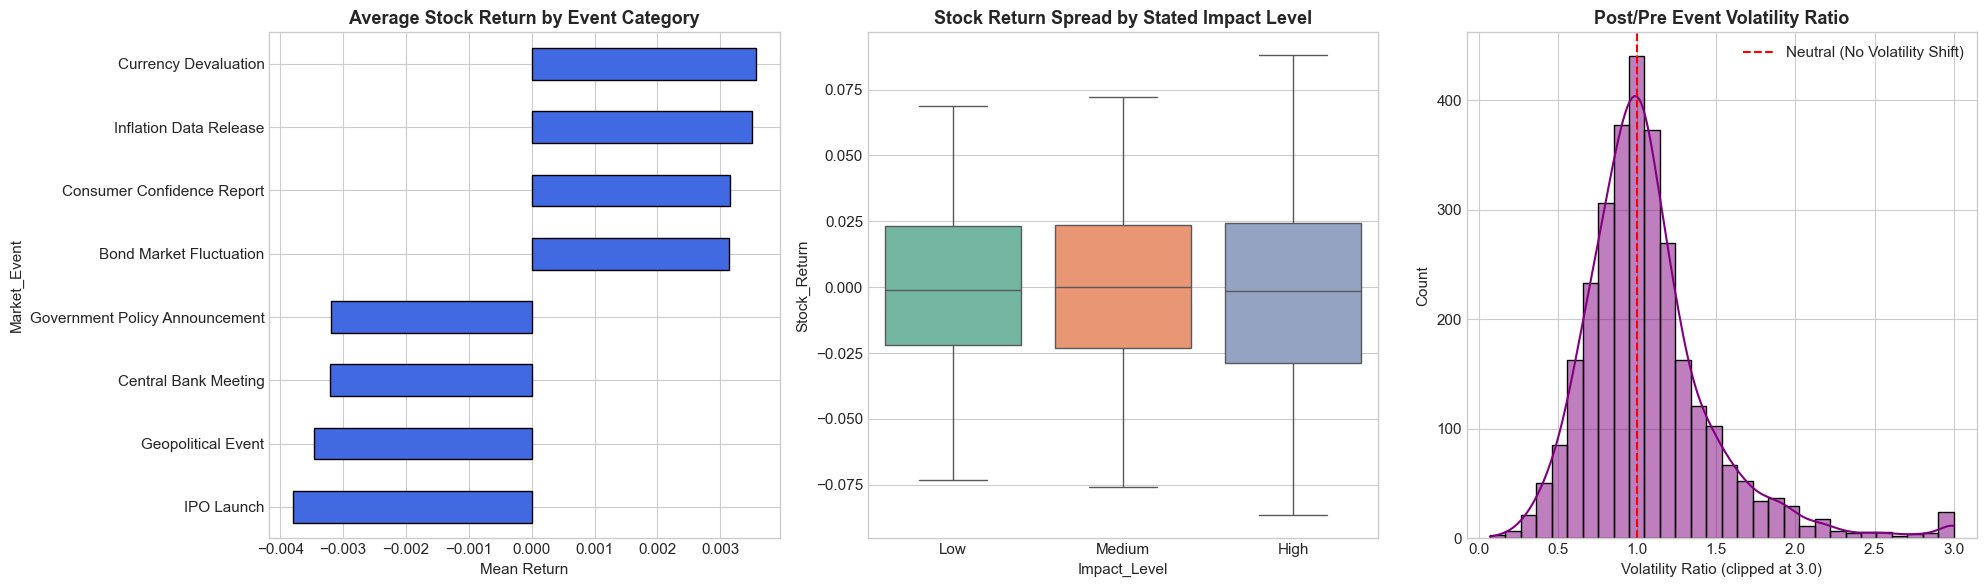

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Panel 1: Top 8 Market Events by Absolute Average Stock Return
event_means = df_cleaned.groupby('Market_Event')['Stock_Return'].mean().sort_values()
top_events = pd.concat([event_means.head(4), event_means.tail(4)])
top_events.plot(kind='barh', ax=axes[0], color='royalblue', edgecolor='black')
axes[0].set_title("Average Stock Return by Event Category", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Mean Return")

# Panel 2: Distribution by Impact Level
sns.boxplot(data=df_cleaned, x='Impact_Level', y='Stock_Return', palette='Set2', ax=axes[1], order=['Low', 'Medium', 'High'])
axes[1].set_title("Stock Return Spread by Stated Impact Level", fontsize=13, fontweight='bold')

# Panel 3: Volatility Ratio Distribution
sns.histplot(df_cleaned['Volatility_Ratio'].clip(0, 3), bins=30, kde=True, color='purple', ax=axes[2])
axes[2].axvline(1.0, color='red', linestyle='--', label='Neutral (No Volatility Shift)')
axes[2].set_title("Post/Pre Event Volatility Ratio", fontsize=13, fontweight='bold')
axes[2].set_xlabel("Volatility Ratio (clipped at 3.0)")
axes[2].legend()

plt.tight_layout()
plt.show()

In [11]:
OUTPUT_PATH = os.path.join("..", "data", "eventecho_master_dataset.csv")
if not os.path.exists(os.path.dirname(OUTPUT_PATH)):
    OUTPUT_PATH = os.path.join("data", "eventecho_master_dataset.csv")

df_cleaned.to_csv(OUTPUT_PATH, index=False)
print(f"Enriched EventEcho Master Dataset saved successfully to: {OUTPUT_PATH}")
print(f"Total Rows: {len(df_cleaned)}, Columns: {len(df_cleaned.columns)}")
print("Columns in Master Dataset:\n", list(df_cleaned.columns))

Enriched EventEcho Master Dataset saved successfully to: ..\data\eventecho_master_dataset.csv
Total Rows: 3024, Columns: 22
Columns in Master Dataset:
 ['Date', 'Headline', 'Source', 'Market_Event', 'Market_Index', 'Index_Change_Percent', 'Trading_Volume', 'Sentiment', 'Sector', 'Impact_Level', 'Related_Company', 'News_Url', 'Market_Return', 'Sector_Beta', 'Stock_Return', 'Stock_Price', 'Days_To_Prev_Event', 'Days_To_Next_Event', 'Is_Confounded', 'Pre_Event_Volatility', 'Post_Event_Volatility', 'Volatility_Ratio']
